# fedOPD - baselines

**Roadmap step 2. Nothing that follows is allowed to skip this.** A forecaster is only interesting
relative to the cheapest thing that could have been done instead, so the numbers established here are
the bar every federated result in `06_federated_forecast.ipynb` has to clear.

Reads `data/canonical/rtt_panel.parquet`. Writes `data/canonical/baselines.csv` and
`data/canonical/series_index.csv`. Nothing is written back to the canonical table.

## What is being forecast

`demand`, the Part_3 new-referral count, per **trust x department x month**. That is the forecast
target named in the column contract, and it is a count of RTT clock starts, not of patients.

## Three decisions, taken here rather than left implicit

**1. The `usable` mask, not `service_exists`.** A zero in the cube means one of three things: the
trust never provided that service, the trust provided it and saw nobody, or the trust filed no return
that month. `03_data_processing.ipynb` separated them. Scoring on a missing return rewards a model for
predicting a zero that never happened, so every series here is masked on `usable`.

**2. A temporal split, never a random one.** The last 12 months are held out; the model never sees
them. A random split would let a series be trained on its own future and would produce excellent,
meaningless numbers.

**3. COVID stays in.** Apr 2020 is a real collapse in referrals, not a data error, and any model
deployed against this collection has to survive shocks of that kind. It sits in the training window,
never in the test window, and is flagged so a later run can be compared with it excluded.

## Metrics, and why not MAPE

Series range from a handful of referrals a month to tens of thousands, so a raw MAE averaged across
series is dominated by the largest trusts.

- **MAE** per series, reported as a distribution rather than a single mean.
- **RMSE** per series. Squaring before averaging makes it punish a single large miss far harder than
  MAE does, which is the right emphasis here: a decision layer is broken by the month it gets badly
  wrong, not by being a little off every month.
- **MASE** - MAE divided by the in-sample MAE of the seasonal-naive forecast on the *training*
  portion of that same series. 1.0 means "no better than repeating last year". Scale-free, and it does
  not divide by the actual value, so a zero month cannot make it infinite.
- **R squared, both ways round, because the two answer different questions.**
  - `R2_pooled` - over every series-month at once, against the mean of all actuals. It looks
    impressive and mostly measures whether the model can tell a large trust from a small one, since
    almost all the variance in the pooled data is *between* series rather than within them.
  - `R2_within` - per series, against that series' **own** test-window mean, reported as a median.
    This asks the question that matters: does the forecast track the shape of this service over the
    year. It is a harsh null and goes negative whenever the forecast is worse than a flat line
    through the series' own mean.

  Quoting `R2_pooled` alone is the standard way to make a forecast look far better than it is. Both
  are printed side by side for that reason.

**MAPE is not used.** It divides by the actual, and this data has real zero months.

In [1]:
import numpy as np                     # arrays and the elementwise arithmetic the metrics are made of
import pandas as pd                    # the table library; the panel arrives as a DataFrame
import matplotlib.pyplot as plt        # the error distribution and example-series plots
from pathlib import Path               # portable path objects

CANON = Path("../data/canonical")      # everything 03_data_processing.ipynb produced
panel = pd.read_parquet(CANON / "rtt_panel.parquet")   # the 126 x 19 x 96 federation cube

TARGET = "demand"                      # the forecast target: Part_3 new RTT periods
H = 12                                 # horizon, months - the length of each evaluation window

# THREE windows, not two. The last 12 months are the TEST year and are sealed: every look at them
# while iterating spends a little of their value, so development is scored on the VALIDATION year
# immediately before it. Set EVAL = "test" once, when the system is built, and report what it says.
EVAL = "validation"                    # "validation" while building | "test" for the final number
SEASON = 12                            # seasonal period: this is monthly data with an annual cycle

# DatetimeIndex, not np.sort: np.sort returns numpy datetime64, which cannot take a %Y-%m format
months = pd.DatetimeIndex(sorted(panel.month.unique()))   # the 96 reporting periods, chronological
test_start = months[-H]                                # first month of the sealed test year
val_start = months[-2 * H]                             # first month of the validation year
split = test_start if EVAL == "test" else val_start    # the boundary everything below uses
print(f"panel     : {len(panel):,} rows, {panel.provider_code.nunique()} trusts x "
      f"{panel.dept.nunique()} depts x {len(months)} months")
print(f"train      : {months[0]:%Y-%m} to {months[months < split][-1]:%Y-%m}  "
      f"({int((months < split).sum())} months)")
print(f"validation : {val_start:%Y-%m} to {months[-H - 1]:%Y-%m}  ({H} months)")
print(f"test       : {test_start:%Y-%m} to {months[-1]:%Y-%m}  ({H} months, SEALED)")
print(f"\nscoring on the {EVAL.upper()} window - development decisions are made here only")
if EVAL == "test":
    print("TEST WINDOW OPENED. Reported once; iterating after seeing it is not honest.")

panel     : 273,600 rows, 150 trusts x 19 depts x 96 months
train      : 2018-04 to 2024-03  (72 months)
validation : 2024-04 to 2025-03  (12 months)
test       : 2025-04 to 2026-03  (12 months, SEALED)

scoring on the VALIDATION window - development decisions are made here only


## 1. The series set

Reshape the long panel into one row per series and one column per month. `pivot` fails loudly if the
key is not unique, which is the check we want: `03` asserts uniqueness, and this would catch it if that
assert were ever removed.

A series is admitted only if **every month in the window is `usable`**. That is the strict rule, and it
is deliberately strict: a series with a hole in it can still be forecast, but a hole in the *test*
window silently scores the model against a month that was never reported. The cost of the rule is
measured below rather than assumed to be small.

In [2]:
# one row per (trust, dept), one column per month - the shape every baseline below operates on
wide = panel.pivot(index=["provider_code", "dept"], columns="month", values=TARGET)
mask = panel.pivot(index=["provider_code", "dept"], columns="month", values="usable")
exists = (panel.groupby(["provider_code", "dept"]).service_exists.first()
               .reindex(wide.index))                   # reindex so the flag lines up with wide's rows

print(f"series in the cube            : {len(wide):,}")
print(f"  service never provided      : {int((~exists).sum()):,}")
print(f"  service exists              : {int(exists.sum()):,}")

# The rule is split in two, because the two windows carry different risks.
# TEST: every month must be usable. A gap here scores a model against a month nobody reported.
# TRAIN: only the most recent MIN_TRAIN months must be usable, and they must adjoin the split, so a
# contiguous block exists to window on. Older gaps are tolerated - a trust that reorganised in 2020
# still has four clean years, and demanding all 96 months discards it for no gain.
MIN_TRAIN = 36                                         # 24-month lookback + 12-month horizon = one window
# the eval window is the H months starting at `split`; a validation run must not see past it
eval_months = (mask.columns >= split) & (mask.columns < split + pd.DateOffset(months=H))
test_ok = mask.loc[:, eval_months].all(axis=1)
train_ok = mask.loc[:, mask.columns < split].iloc[:, -MIN_TRAIN:].all(axis=1)
keep = exists & test_ok & train_ok

print(f"  usable across the whole {EVAL} window : {int((exists & test_ok).sum()):,}")
print(f"  and the last {MIN_TRAIN} training months  : {int(keep.sum()):,}")
print(f"  excluded                            : {int((exists & ~keep).sum()):,}")

dropped = exists & ~keep                               # cost of the rule, measured not assumed
lost = wide[dropped].sum().sum() / wide[exists].sum().sum() * 100
print(f"demand carried by the excluded series: {lost:.2f}% of all panel demand")
print(f"strictest alternative, usable in all {len(months)} months: {int(mask.all(axis=1).sum()):,} series")

series = wide[keep].copy()                             # the evaluation set
series.columns = pd.to_datetime(series.columns)        # month columns as real dates
train = series.loc[:, series.columns < split]          # everything strictly before the split
# exactly the H months being scored, and nothing beyond them - so a "validation" run cannot
# see the test year sitting after it
test = series.loc[:, (series.columns >= split) &
                     (series.columns < split + pd.DateOffset(months=H))]
assert test.shape[1] == H, f"eval window is {test.shape[1]} months, expected {H}"
print(f"\nevaluation set : {len(series):,} series, "
      f"{train.shape[1]} train months, {test.shape[1]} scored months ({EVAL})")


series in the cube            : 2,850
  service never provided      : 652
  service exists              : 2,198
  usable across the whole validation window : 2,197
  and the last 36 training months  : 2,085
  excluded                            : 113
demand carried by the excluded series: 5.68% of all panel demand
strictest alternative, usable in all 96 months: 1,870 series

evaluation set : 2,085 series, 72 train months, 12 scored months (validation)


## 2. The baselines

Four, in increasing order of what they assume.

| | forecast for month T+h | what it assumes |
|---|---|---|
| `naive` | the last observed value | nothing changes |
| `seasonal_naive` | the value 12 months earlier | last year repeats |
| `mean12` | the mean of the last 12 months | the level is flat and noisy |
| `drift` | last value + h x average monthly change over the last 12 | the recent trend continues |

**Stated in advance, and then falsified by the run.** `seasonal_naive` was written down here as the
one to beat, on the reasoning that referrals have a strong annual shape - August and December are low
because clinics and referrers take leave. Measured on the 1,870-series panel it came **third of four**
(median MASE 0.650), behind both `mean12` (0.576) and `naive` (0.591).

The reading: at trust x specialty granularity the annual pattern is buried in month-to-month noise. It
is real in the national aggregate and it does not survive disaggregation to a single department in a
single trust. Left in place rather than quietly rewritten, because a prediction that was wrong is
worth more on the page than one edited to match the result.

All four are computed from a **single forecast origin**, the last training month, and projected H
months forward. That is the honest version of what the deployed system would do: it forecasts a year
from where it stands, rather than being handed each month's truth as it goes.

In [3]:
tr = train.to_numpy(dtype=float)                       # (n_series, n_train_months)
te = test.to_numpy(dtype=float)                        # (n_series, H)
n = len(tr)

last = tr[:, -1:]                                      # the final training month, per series
season = tr[:, -SEASON:]                               # the last full year of training data
mean12 = season.mean(axis=1, keepdims=True)            # flat level
# average month-on-month change over the last year: (end - start) / steps, the classic drift term
slope = (tr[:, -1] - tr[:, -SEASON]) / (SEASON - 1)

steps = np.arange(1, H + 1)                            # h = 1..12

fc = {
    "naive":          np.repeat(last, H, axis=1),                     # flat at the last value
    # h-1 indexes into the last year: h=1 takes the month 12 back, h=12 takes the month 1 back
    "seasonal_naive": season[:, (steps - 1) % SEASON],
    "mean12":         np.repeat(mean12, H, axis=1),                   # flat at the annual mean
    "drift":          last + slope[:, None] * steps,                  # straight line from the origin
}
for k in fc:
    fc[k] = np.clip(fc[k], 0, None)                    # a negative referral count is not a forecast
    assert fc[k].shape == te.shape, f"{k} forecast is the wrong shape"

print(f"{n:,} series x {H} months forecast by {len(fc)} baselines")
for k, v in fc.items():
    print(f"  {k:16s} first series, h=1..3: {np.round(v[0, :3], 1)}   actual: {np.round(te[0, :3], 1)}")

2,085 series x 12 months forecast by 4 baselines
  naive            first series, h=1..3: [1638. 1638. 1638.]   actual: [1781. 1799. 1742.]
  seasonal_naive   first series, h=1..3: [1499. 1679. 1904.]   actual: [1781. 1799. 1742.]
  mean12           first series, h=1..3: [1696.5 1696.5 1696.5]   actual: [1781. 1799. 1742.]
  drift            first series, h=1..3: [1650.6 1663.3 1675.9]   actual: [1781. 1799. 1742.]


## 3. Scoring

MASE needs an in-sample scale per series. The denominator is the mean absolute **seasonal-naive** error
over the training portion only - `mean(|y[t] - y[t-12]|)`. Using the training portion is the point: a
denominator computed on the test data would leak the answer into the metric.

A series whose denominator is zero is one that repeated itself exactly for the whole training window.
Those are dropped from the MASE table and counted, rather than being given an infinite score.

In [4]:
# in-sample seasonal-naive error, training portion only - the MASE denominator
scale = np.abs(tr[:, SEASON:] - tr[:, :-SEASON]).mean(axis=1)
degenerate = scale <= 0                                # perfectly repeating series
print(f"series with a zero MASE denominator (constant year on year): {int(degenerate.sum())}")

# SS_tot for the two R squareds. Pooled uses one grand mean; within uses each series' own mean, which
# is the harsher and more honest null - a flat line at the series' own level.
ss_tot_pooled = ((te - te.mean()) ** 2).sum()
ss_tot_within = ((te - te.mean(axis=1, keepdims=True)) ** 2).sum(axis=1)

def score(pred):
    # every metric for one (n_series, H) forecast array
    err = pred - te
    mae = np.abs(err).mean(axis=1)                     # one MAE per series
    rmse = np.sqrt((err ** 2).mean(axis=1))            # one RMSE per series
    mase = np.where(degenerate, np.nan, mae / np.where(degenerate, 1, scale))
    ss_res = (err ** 2).sum(axis=1)
    r2_within = np.where(ss_tot_within > 0, 1 - ss_res / np.where(ss_tot_within > 0, ss_tot_within, 1),
                         np.nan)                       # a flat test window has no variance to explain
    return {
        "MAE_mean": mae.mean(), "MAE_median": np.median(mae),
        "RMSE_mean": rmse.mean(), "RMSE_median": np.median(rmse),
        "RMSE_pooled": np.sqrt((err ** 2).mean()),     # over every series-month at once
        "MASE_mean": np.nanmean(mase), "MASE_median": np.nanmedian(mase),
        "R2_pooled": 1 - ss_res.sum() / ss_tot_pooled,        # flattered by between-series variance
        "R2_within_median": np.nanmedian(r2_within),          # the one that answers the real question
    }, mae, rmse, r2_within

rows = [{"baseline": name, **score(pred)[0], "pct_series_beating_snaive": np.nan}
        for name, pred in fc.items()]

scores = pd.DataFrame(rows).set_index("baseline")

# how often each baseline beats the seasonal-naive one, series by series. A mean can be carried by a
# handful of large trusts; this says whether the win is general.
snaive_mae = np.abs(fc["seasonal_naive"] - te).mean(axis=1)
for name in fc:
    m = np.abs(fc[name] - te).mean(axis=1)
    scores.loc[name, "pct_series_beating_snaive"] = (m < snaive_mae).mean() * 100

print(scores.round(3).to_string())
print()
best = scores.MASE_median.idxmin()
print(f"best baseline on median MASE: {best} ({scores.MASE_median.min():.3f})")
print("MASE 1.0 = no better than repeating last year. Below 1 is a real gain, above 1 is worse.")
print()
print(f"note the two R squareds for {best}: pooled {scores.loc[best, 'R2_pooled']:.3f} against "
      f"within-series median {scores.loc[best, 'R2_within_median']:.3f}.")
print("The gap between them is the between-series variance. Pooled R2 rewards knowing which trust is")
print("large; within-series R2 asks whether the year's shape was predicted, and is the honest one.")

series with a zero MASE denominator (constant year on year): 15
                MAE_mean  MAE_median  RMSE_mean  RMSE_median  RMSE_pooled  MASE_mean  MASE_median  R2_pooled  R2_within_median  pct_series_beating_snaive
baseline                                                                                                                                                 
naive             92.618      59.667    111.382       72.778      186.731      0.692        0.510      0.968            -0.667                     62.782
seasonal_naive   111.997      71.500    136.633       87.266      234.267      0.813        0.617      0.949            -1.488                      0.000
mean12            96.112      59.208    114.493       72.165      192.331      0.710        0.512      0.966            -0.492                     74.484
drift            122.828      73.023    145.016       88.336      262.002      0.911        0.641      0.936            -1.451                     44.988

best baseli

## 4. Error by horizon and by specialty

A single averaged number hides the two things that matter for the decision layer: whether the forecast
degrades with the horizon it is asked to cover, and whether it fails unevenly across specialties. The
agentic layer projects several months ahead, so h=12 error is the one that governs an escalation, not
h=1.

In [5]:
# error by horizon: the number the agentic layer's projection depth depends on
per_h = pd.DataFrame({name: np.abs(pred - te).mean(axis=0) for name, pred in fc.items()},
                     index=[f"h={h}" for h in steps])
print("mean absolute error by horizon (all series, referrals per month):")
print(per_h.round(1).to_string())

# error by specialty, on the best baseline, normalised so specialties are comparable
dept = series.index.get_level_values("dept")
mase_best = np.abs(fc[best] - te).mean(axis=1) / np.where(degenerate, np.nan, scale)
by_dept = (pd.DataFrame({"dept": dept, "mase": mase_best})
             .groupby("dept").mase.agg(["median", "count"]).sort_values("median"))
print(f"\nMASE by specialty, {best} baseline (median over series):")
print(by_dept.round(3).to_string())

mean absolute error by horizon (all series, referrals per month):
      naive  seasonal_naive  mean12  drift
h=1    66.0           150.1    77.3   65.9
h=2    83.8           119.3    90.2   84.4
h=3    71.1           120.3    77.7   83.0
h=4   101.7           123.0   104.5  103.5
h=5    82.9           105.8    83.0  113.4
h=6    80.9           100.8    81.2  114.1
h=7   118.4           115.7   119.2  125.7
h=8    86.4            95.9    87.2  130.1
h=9    98.5            98.2   104.0  170.8
h=10  112.2           101.9   112.0  148.2
h=11   91.7            95.2    95.9  165.4
h=12  117.8           117.8   121.1  169.4

MASE by specialty, naive baseline (median over series):
         median  count
dept                  
C_130     0.381    109
C_300     0.393    114
C_100     0.408    119
C_140     0.413    112
X_OTHER   0.442    139
C_400     0.450    102
C_120     0.473    113
C_150     0.486     49
C_110     0.494    123
C_101     0.518    117
C_430     0.537    115
C_502     0.544    

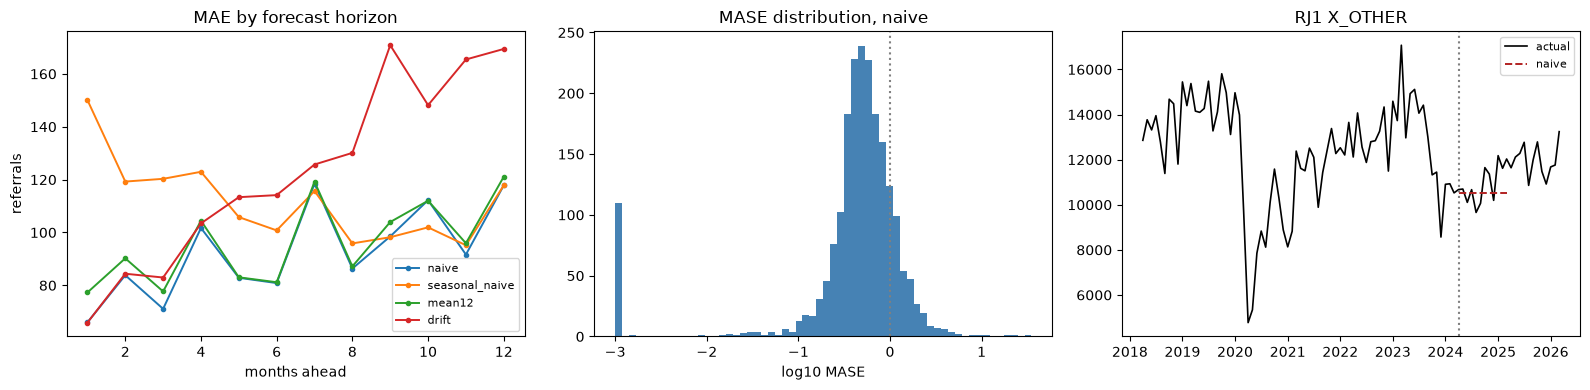

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

for name in fc:                                        # how error grows with horizon
    ax[0].plot(steps, per_h[name], lw=1.4, marker="o", ms=3, label=name)
ax[0].set_title("MAE by forecast horizon"); ax[0].set_xlabel("months ahead")
ax[0].set_ylabel("referrals"); ax[0].legend(fontsize=8)

# the MASE distribution, log scale because it spans orders of magnitude across series
m = mase_best[np.isfinite(mase_best)]
ax[1].hist(np.log10(np.clip(m, 1e-3, None)), bins=60, color="steelblue")
ax[1].axvline(0, color="grey", ls=":")                 # log10(1) = 0, the seasonal-naive line
ax[1].set_title(f"MASE distribution, {best}"); ax[1].set_xlabel("log10 MASE")

# one real series with the split marked, so the shape being forecast is visible
i = int(np.argsort(-series.to_numpy().sum(axis=1))[0])  # the largest series by total demand
ax[2].plot(series.columns, series.iloc[i], lw=1.2, color="black", label="actual")
ax[2].plot(test.columns, fc[best][i], lw=1.4, ls="--", color="firebrick", label=best)
ax[2].axvline(split, color="grey", ls=":")             # where the model stops seeing data
ax[2].set_title(f"{series.index[i][0]} {series.index[i][1]}"); ax[2].legend(fontsize=8)
plt.tight_layout()

## 5. Performance summary

Four views of the same forecast, because a table of averages hides the shape of the failure.

- **Predicted against actual**, every series-month. Points on the diagonal are right. Systematic
  departure from the diagonal is bias, and it matters more than scatter: a forecast that is wrong in
  one direction every month walks the projected backlog steadily away from the truth.
- **Residual distribution**, which says whether the errors are centred on zero or the forecast is
  quietly running high or low across the board.
- **RMSE by horizon**, which is what governs how far ahead the decision layer can plan.
- **Metrics side by side**, all four baselines.

median scaled residual: -0.027  (under-forecasting on balance)


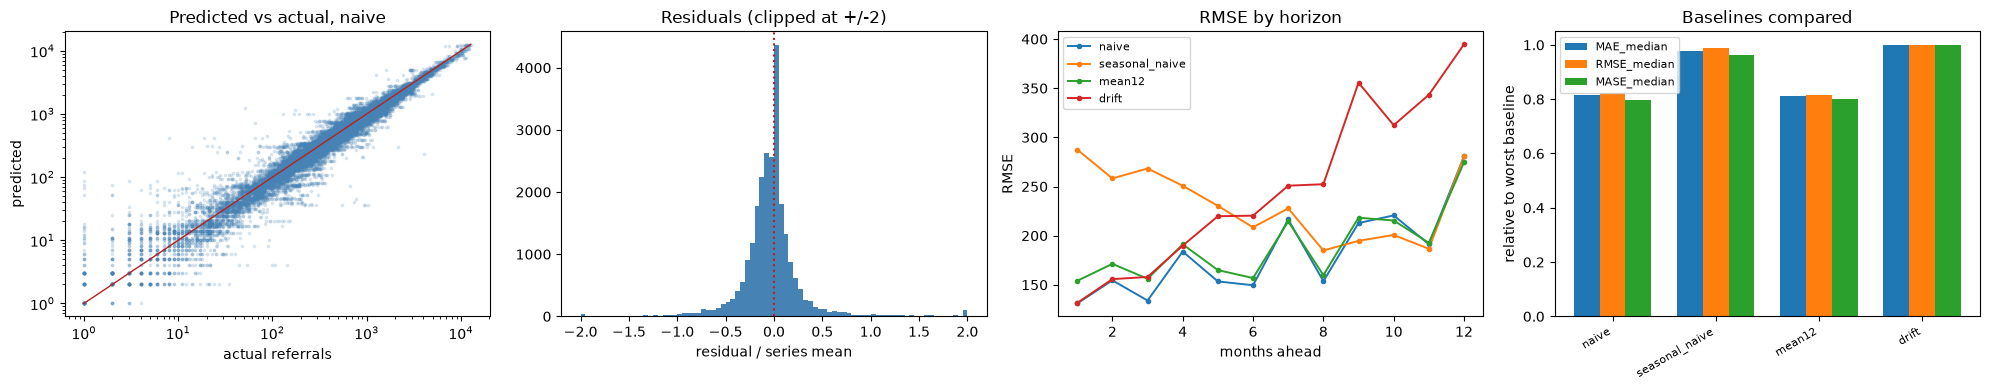

In [7]:
fig, ax = plt.subplots(1, 4, figsize=(20, 4))
pred_best = fc[best]

# 1. predicted vs actual, log-log because series sizes span four orders of magnitude
a, p = te.ravel(), pred_best.ravel()
keep = (a > 0) & (p > 0)                               # log axes cannot show the zeros
ax[0].scatter(a[keep], p[keep], s=3, alpha=0.15, color="steelblue")
lim = [max(1, a[keep].min()), a.max()]
ax[0].plot(lim, lim, color="firebrick", lw=1)          # the diagonal: a perfect forecast
ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("actual referrals"); ax[0].set_ylabel("predicted")
ax[0].set_title(f"Predicted vs actual, {best}")

# 2. residuals, scaled by each series' own mean so large and small series are comparable
resid = (pred_best - te) / (te.mean(axis=1, keepdims=True) + 1)
ax[1].hist(np.clip(resid.ravel(), -2, 2), bins=80, color="steelblue")
ax[1].axvline(0, color="firebrick", ls=":")            # zero: unbiased
ax[1].set_xlabel("residual / series mean"); ax[1].set_title("Residuals (clipped at +/-2)")
print(f"median scaled residual: {np.median(resid):+.3f}  "
      f"({'over' if np.median(resid) > 0 else 'under'}-forecasting on balance)")

# 3. RMSE by horizon, the number that limits planning depth
for name, pred in fc.items():
    ax[2].plot(steps, np.sqrt(((pred - te) ** 2).mean(axis=0)), lw=1.4, marker="o", ms=3, label=name)
ax[2].set_xlabel("months ahead"); ax[2].set_ylabel("RMSE"); ax[2].legend(fontsize=8)
ax[2].set_title("RMSE by horizon")

# 4. the metrics table as a chart, normalised so four different scales fit on one axis
show = scores[["MAE_median", "RMSE_median", "MASE_median"]]
norm_show = show / show.max()                          # each metric scaled to its own worst baseline
x = np.arange(len(show))
for i, c in enumerate(show.columns):
    ax[3].bar(x + i * 0.25, norm_show[c], width=0.25, label=c)
ax[3].set_xticks(x + 0.25); ax[3].set_xticklabels(show.index, rotation=30, ha="right", fontsize=8)
ax[3].set_ylabel("relative to worst baseline"); ax[3].legend(fontsize=8)
ax[3].set_title("Baselines compared")
plt.tight_layout()

## 6. Write the bar

`baselines.csv` is the table `06_federated_forecast.ipynb` compares against. `series_index.csv` fixes
**which** series are in the evaluation set and where the split falls, so the federated run scores on
exactly the same set - comparing two models on two different series sets is not a comparison.

In [8]:
scores.to_csv(CANON / "baselines.csv")                 # the bar every later result must clear
per_h.to_csv(CANON / "baselines_by_horizon.csv")

idx = series.index.to_frame(index=False)               # provider_code, dept
idx["split_month"] = split                             # the train/test boundary, fixed for all models
idx["horizon"] = H
idx["mase_scale"] = scale                              # the per-series denominator, so it is not recomputed
idx.to_csv(CANON / "series_index.csv", index=False)

print(f"written: baselines.csv, baselines_by_horizon.csv, series_index.csv")
print(f"evaluation set fixed at {len(idx):,} series, split {split:%Y-%m}, horizon {H}")
print()
print("The bar, on the numbers above:")
print(f"  beat median MASE {scores.MASE_median.min():.3f} ({best}) on the SAME series and split,")
print("  and beat it at h=12, not only at h=1. A model that only wins at short horizons does not")
print("  help a decision layer that projects a year forward.")

written: baselines.csv, baselines_by_horizon.csv, series_index.csv
evaluation set fixed at 2,085 series, split 2024-04, horizon 12

The bar, on the numbers above:
  beat median MASE 0.510 (naive) on the SAME series and split,
  and beat it at h=12, not only at h=1. A model that only wins at short horizons does not
  help a decision layer that projects a year forward.


## 7. The compiled, normalised dataset

One CSV holding every eligible series across all 96 months, in tidy form: one row per
site x department x month, the eight raw measures, and a normalised copy of each.

**The scaler is fitted on training months only.** Fitting it over all 96 would push the mean and
spread of the held-out year into the numbers a model trains on, which is leakage - quiet, and it
inflates every result that follows. The scaler parameters are written alongside so the normalisation
is reversible and auditable rather than baked in.

`z = (x - train_mean) / train_std`, per series. Series whose training window is constant have zero
spread and would divide by zero; their `std` is set to 1, which leaves `z = 0` for a flat series
rather than producing infinities.

Both the raw and the normalised columns are kept in one file. A forecast has to be reported in
referrals, so throwing the raw values away would mean inverting the scaler to say anything a planner
could read.

In [9]:
NORM_MEASURES = ["demand", "completed_admitted", "completed_nonadmitted", "completed",
                 "waiting", "waiting_gt18", "waiting_gt52", "waiting_dta"]

eligible_keys = series.index                                   # the series 05 admitted, in its order
long = panel.set_index(["provider_code", "dept"]).loc[eligible_keys].reset_index()

train_rows = long[long.month < split]                          # scaler sees the training window only
stats = train_rows.groupby(["provider_code", "dept"])[NORM_MEASURES].agg(["mean", "std"])
stats.columns = [f"{m}_{s}" for m, s in stats.columns]         # flatten the MultiIndex
for m in NORM_MEASURES:
    stats[f"{m}_std"] = stats[f"{m}_std"].replace(0, 1).fillna(1)   # flat series -> z = 0, not inf

long = long.merge(stats, on=["provider_code", "dept"], how="left")
for m in NORM_MEASURES:
    long[f"{m}_z"] = (long[m] - long[f"{m}_mean"]) / long[f"{m}_std"]

long["split"] = np.where(long.month < split, "train", "test")  # which window each row belongs to
out_cols = (["provider_code", "dept", "icb", "month", "split"] + NORM_MEASURES
            + [f"{m}_z" for m in NORM_MEASURES])
out = long[out_cols].sort_values(["provider_code", "dept", "month"])

out.to_csv(CANON / "rtt_normalised.csv", index=False)
stats.reset_index().to_csv(CANON / "rtt_normalised_scalers.csv", index=False)

# a scaler fitted on training months must leave those months at mean 0, sd 1. Anything else means it
# was fitted on the wrong rows, which is exactly the leakage this section exists to avoid.
# NOT `tr` - that name already holds the numpy training matrix used by every baseline above,
# and rebinding it here silently broke the section that follows.
train_rows_z = out[out.split == "train"]
assert abs(train_rows_z.demand_z.mean()) < 1e-6, "training rows are not centred - wrong window"

print(f"written: rtt_normalised.csv   {len(out):,} rows x {len(out_cols)} columns")
print(f"         rtt_normalised_scalers.csv   {len(stats):,} series x {len(stats.columns)} parameters")
print(f"  {out.provider_code.nunique()} sites x {out.dept.nunique()} departments x "
      f"{out.month.nunique()} months, {len(eligible_keys):,} series")
print(f"  months {out.month.min():%Y-%m} to {out.month.max():%Y-%m}, "
      f"train {(out.split == 'train').sum():,} rows / test {(out.split == 'test').sum():,} rows")
print()
print("training-window check, demand_z:")
print(f"  mean {train_rows_z.demand_z.mean():+.6f}  sd {train_rows_z.demand_z.std():.4f}   (0.000 and 1.000 by construction)")
print(f"  test-window mean {out[out.split == 'test'].demand_z.mean():+.4f} - free to differ, and does")


written: rtt_normalised.csv   200,160 rows x 21 columns
         rtt_normalised_scalers.csv   2,085 series x 16 parameters
  141 sites x 19 departments x 96 months, 2,085 series
  months 2018-04 to 2026-03, train 150,120 rows / test 50,040 rows

training-window check, demand_z:
  mean -0.000000  sd 0.9895   (0.000 and 1.000 by construction)
  test-window mean +0.5475 - free to differ, and does


## 8. The question the business actually asks — is this service growing?

Median MASE says how close a forecast lands each month. It is **not** the quantity a capacity decision
turns on. D-07 splits on whether growth is *sustained*, and that is a different question with a
different answer: a method can be poor at predicting March and still be reliable at predicting
"this department is on a growth path".

So this section scores the same four baselines on the decision-relevant question, on the same
validation window:

**growth = mean demand over the scored window ÷ mean demand over the last 12 training months − 1**

Two ways, because a threshold is arbitrary and a correlation is not:

1. **Continuous** — how well does predicted growth track actual growth across the 2,085 services.
2. **Classified** — treating growth above `GROWTH_THRESH` as "sustained", how often is the call right,
   reported against the **base rate** and against always predicting the majority class. Accuracy on an
   imbalanced problem is meaningless without both, and quoting it alone is the standard way to make a
   classifier look good.

`GROWTH_THRESH` is set to 5% and fixed before running. It is not tuned to make a number look better.

In [10]:
GROWTH_THRESH = 0.05                                   # 5% year-on-year, declared before the run

base = tr[:, -SEASON:].mean(axis=1)                    # last 12 training months, the reference level
actual_growth = te.mean(axis=1) / np.where(base > 0, base, np.nan) - 1

rows = []
for name, pred in fc.items():
    pg = pred.mean(axis=1) / np.where(base > 0, base, np.nan) - 1     # each method's implied growth
    ok = np.isfinite(pg) & np.isfinite(actual_growth)
    truth, call = actual_growth[ok] > GROWTH_THRESH, pg[ok] > GROWTH_THRESH
    tp = int((truth & call).sum()); fp = int((~truth & call).sum()); fn = int((truth & ~call).sum())
    rows.append({
        "baseline": name,
        "corr_with_actual_growth": np.corrcoef(pg[ok], actual_growth[ok])[0, 1],
        "direction_acc_pct": float((np.sign(pg[ok]) == np.sign(actual_growth[ok])).mean() * 100),
        "accuracy_pct": float((truth == call).mean() * 100),
        "precision_pct": tp / (tp + fp) * 100 if tp + fp else np.nan,
        "recall_pct": tp / (tp + fn) * 100 if tp + fn else np.nan,
    })
growth = pd.DataFrame(rows).set_index("baseline")

ok = np.isfinite(actual_growth)
rate = float((actual_growth[ok] > GROWTH_THRESH).mean() * 100)
print(f"services scored: {int(ok.sum()):,}")
print(f"base rate - genuinely grew more than {GROWTH_THRESH:.0%}: {rate:.1f}%")
print(f"always predicting the majority class would score: {max(rate, 100 - rate):.1f}% accuracy")
print(f"median actual growth across services: {np.nanmedian(actual_growth) * 100:+.1f}%")
print()
print(growth.round(2).to_string())
print()
print("Read `accuracy_pct` ONLY against the majority-class line above. Read `corr` and `recall`")
print("first: a method that never calls growth scores well on accuracy and is useless for planning.")


services scored: 1,978
base rate - genuinely grew more than 5%: 45.9%
always predicting the majority class would score: 54.1% accuracy
median actual growth across services: +3.7%

                corr_with_actual_growth  direction_acc_pct  accuracy_pct  precision_pct  recall_pct
baseline                                                                                           
naive                              0.01              62.64         64.46          68.67       41.52
seasonal_naive                      NaN               0.40         54.10            NaN        0.00
mean12                            -0.00              23.56         54.10            NaN        0.00
drift                              0.02              66.33         65.57          62.19       63.77

Read `accuracy_pct` ONLY against the majority-class line above. Read `corr` and `recall`
first: a method that never calls growth scores well on accuracy and is useless for planning.


C:\Users\heave\AppData\Local\Programs\Python\Python312\Lib\site-packages\numpy\lib\_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\heave\AppData\Local\Programs\Python\Python312\Lib\site-packages\numpy\lib\_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


written: growth_detection.csv

The quadrants that matter for D-07 are top-left and bottom-right of the left panel: services
called as growing that shrank, and growing services that were missed. The second is the
expensive one - a missed growth trend is capacity that never gets built.


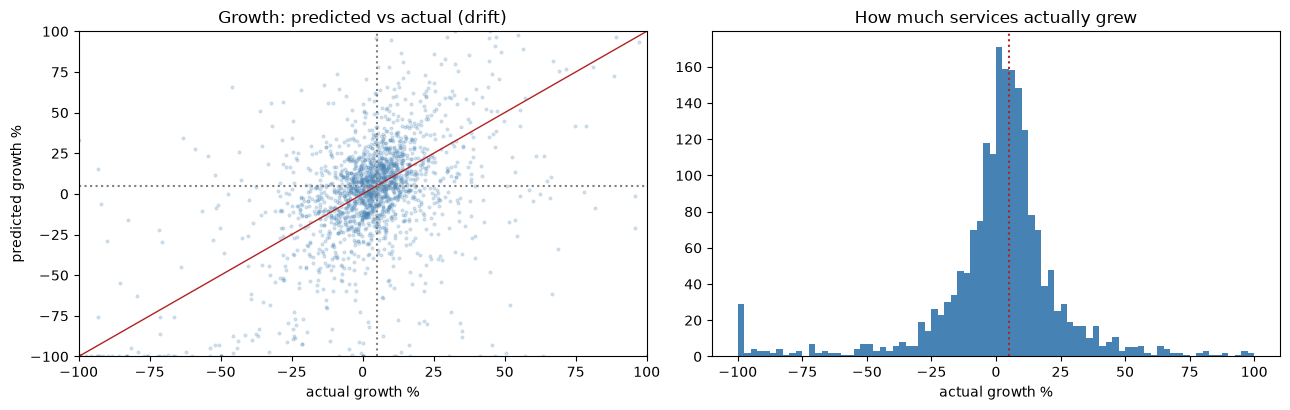

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))

bestg = growth.corr_with_actual_growth.idxmax()         # the method that tracks growth best
pg = fc[bestg].mean(axis=1) / np.where(base > 0, base, np.nan) - 1
ok = np.isfinite(pg) & np.isfinite(actual_growth)

lim = np.nanpercentile(np.abs(actual_growth[ok]), 98)   # clip the tail so the bulk is visible
ax[0].scatter(actual_growth[ok] * 100, pg[ok] * 100, s=4, alpha=0.2, color="steelblue")
ax[0].plot([-lim * 100, lim * 100], [-lim * 100, lim * 100], color="firebrick", lw=1)
ax[0].axhline(GROWTH_THRESH * 100, color="grey", ls=":"); ax[0].axvline(GROWTH_THRESH * 100, color="grey", ls=":")
ax[0].set_xlim(-lim * 100, lim * 100); ax[0].set_ylim(-lim * 100, lim * 100)
ax[0].set_xlabel("actual growth %"); ax[0].set_ylabel("predicted growth %")
ax[0].set_title(f"Growth: predicted vs actual ({bestg})")

ax[1].hist(actual_growth[ok] * 100, bins=80, range=(-lim * 100, lim * 100), color="steelblue")
ax[1].axvline(GROWTH_THRESH * 100, color="firebrick", ls=":")
ax[1].set_xlabel("actual growth %"); ax[1].set_title("How much services actually grew")
plt.tight_layout()

growth.to_csv(CANON / "growth_detection.csv")
print(f"written: growth_detection.csv\n")
print("The quadrants that matter for D-07 are top-left and bottom-right of the left panel: services")
print("called as growing that shrank, and growing services that were missed. The second is the")
print("expensive one - a missed growth trend is capacity that never gets built.")
